# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Rakha Makarim | 5054251010 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan.
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_style("whitegrid")


In [2]:
# Load dataset.
# Sesuaikan nama file dengan file dataset yang digunakan.
df = pd.read_csv("../Dataset/insurance.csv")


In [3]:
# Tampilkan beberapa baris pertama dataset.
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Tampilkan informasi dataset.
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
# Periksa missing value.
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nTotal missing value :", df.isnull().sum().sum())
print("Baris duplikat      :", df.duplicated().sum())

# Drop baris duplikat supaya data bersih.
df.drop_duplicates(inplace=True)
print("Jumlah baris setelah drop duplikat:", len(df))


Missing value per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing value : 0
Baris duplikat      : 1
Jumlah baris setelah drop duplikat: 1337


In [6]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe()


,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
for col in df.select_dtypes(exclude="number").columns:
    print(f"--- {col} ---")
    print(df[col].value_counts(), "\n")


--- sex ---
sex
male      675
female    662
Name: count, dtype: int64 

--- smoker ---
smoker
no     1063
yes     274
Name: count, dtype: int64 

--- region ---
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64 



## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


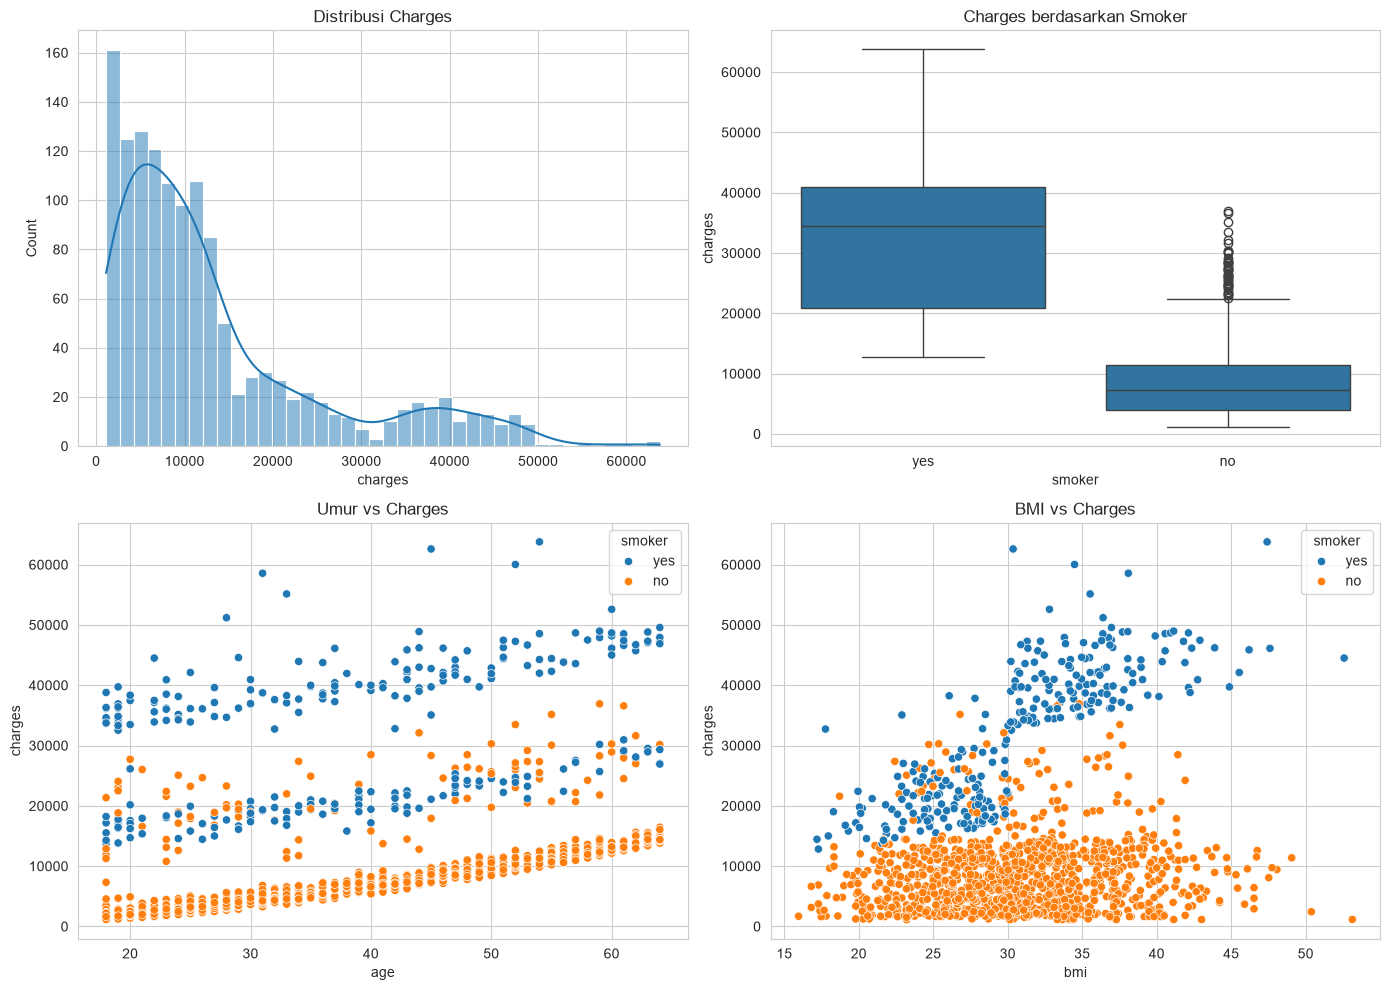

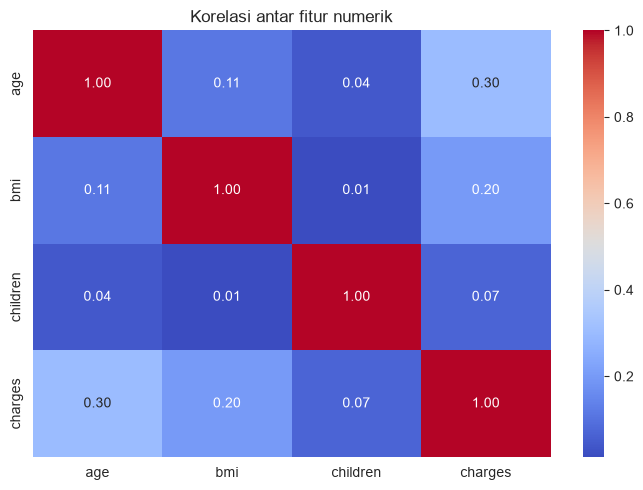

In [8]:
# EDA sederhana: distribusi target dan pengaruh fitur utama terhadap charges.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df["charges"], bins=40, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribusi Charges")

sns.boxplot(x="smoker", y="charges", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Charges berdasarkan Smoker")

sns.scatterplot(x="age", y="charges", hue="smoker", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Umur vs Charges")

sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df, ax=axes[1, 1])
axes[1, 1].set_title("BMI vs Charges")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi antar fitur numerik")
plt.tight_layout()
plt.show()


# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [9]:
# Pisahkan fitur (X) dan target (y).
X = df.drop("charges", axis=1)
y = df["charges"]


In [10]:
# Identifikasi kolom numerik dan kategorikal.
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

print("Fitur numerik    :", num_cols)
print("Fitur kategorikal:", cat_cols)


Fitur numerik    : ['age', 'bmi', 'children']
Fitur kategorikal: ['sex', 'smoker', 'region']


In [11]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train set:", X_train.shape)
print("Test set :", X_test.shape)


Train set: (1069, 6)
Test set : (268, 6)


In [12]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
# Untuk model yang memerlukan scaling (Linear, Polynomial, Ridge, Lasso, SVR).
preprocess_scaled = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

# Decision Tree tidak memerlukan scaling, cukup one-hot encoding.
preprocess_tree = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
], remainder="passthrough")


# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [13]:
# Inisialisasi dan latih Linear Regression.
pipe_lin = Pipeline([
    ("preprocess", preprocess_scaled),
    ("model", LinearRegression()),
])
pipe_lin.fit(X_train, y_train)
print("Linear Regression selesai dilatih.")


Linear Regression selesai dilatih.


In [14]:
# Lakukan prediksi pada test set.
y_pred_lin = pipe_lin.predict(X_test)


## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [15]:
# Buat fitur polynomial dan latih model.
pipe_poly = Pipeline([
    ("preprocess", preprocess_scaled),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("model", LinearRegression()),
])

# Eksperimen degree 2 dan 3, pilih berdasarkan R2 validasi 5-fold.
poly_scores = {}
for degree in [2, 3]:
    pipe_poly.set_params(poly__degree=degree)
    poly_scores[degree] = cross_val_score(
        pipe_poly, X_train, y_train, cv=5, scoring="r2"
    ).mean()

best_degree = max(poly_scores, key=poly_scores.get)
print("R2 validasi tiap degree:", poly_scores)
print("Degree terbaik         :", best_degree)

pipe_poly.set_params(poly__degree=best_degree)
pipe_poly.fit(X_train, y_train)
print("Polynomial Regression selesai dilatih.")


R2 validasi tiap degree: {2: np.float64(0.8226240368091032), 3: np.float64(0.8099452146174189)}
Degree terbaik         : 2
Polynomial Regression selesai dilatih.


In [16]:
# Lakukan prediksi pada test set.
y_pred_poly = pipe_poly.predict(X_test)


## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [17]:
# Inisialisasi dan latih Ridge Regression.
pipe_ridge = Pipeline([
    ("preprocess", preprocess_scaled),
    ("model", Ridge()),
])

# Eksperimen nilai alpha, pilih berdasarkan R2 validasi 5-fold.
ridge_scores = {}
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]:
    pipe_ridge.set_params(model__alpha=alpha)
    ridge_scores[alpha] = cross_val_score(
        pipe_ridge, X_train, y_train, cv=5, scoring="r2"
    ).mean()

best_alpha_ridge = max(ridge_scores, key=ridge_scores.get)
print("R2 validasi tiap alpha:", ridge_scores)
print("Alpha terbaik         :", best_alpha_ridge)

pipe_ridge.set_params(model__alpha=best_alpha_ridge)
pipe_ridge.fit(X_train, y_train)
print("Ridge Regression selesai dilatih.")


R2 validasi tiap alpha: {0.01: np.float64(0.7257588033124269), 0.1: np.float64(0.725771512370485), 1.0: np.float64(0.7258656187605561), 10.0: np.float64(0.7239573804021994), 100.0: np.float64(0.6161073602266465), 1000.0: np.float64(0.21913441251025936)}
Alpha terbaik         : 1.0
Ridge Regression selesai dilatih.


In [18]:
# Lakukan prediksi pada test set.
y_pred_ridge = pipe_ridge.predict(X_test)


## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [19]:
# Inisialisasi dan latih Lasso Regression.
pipe_lasso = Pipeline([
    ("preprocess", preprocess_scaled),
    ("model", Lasso(max_iter=10000)),
])

# Eksperimen nilai alpha, pilih berdasarkan R2 validasi 5-fold.
lasso_scores = {}
for alpha in [1, 10, 100, 1000, 10000]:
    pipe_lasso.set_params(model__alpha=alpha)
    lasso_scores[alpha] = cross_val_score(
        pipe_lasso, X_train, y_train, cv=5, scoring="r2"
    ).mean()

best_alpha_lasso = max(lasso_scores, key=lasso_scores.get)
print("R2 validasi tiap alpha:", lasso_scores)
print("Alpha terbaik         :", best_alpha_lasso)

pipe_lasso.set_params(model__alpha=best_alpha_lasso)
pipe_lasso.fit(X_train, y_train)
print("Lasso Regression selesai dilatih.")


R2 validasi tiap alpha: {1: np.float64(0.7257672530372961), 10: np.float64(0.7258734398869736), 100: np.float64(0.7256932196035014), 1000: np.float64(0.6647896062359953), 10000: np.float64(-0.0011476636903515302)}
Alpha terbaik         : 10
Lasso Regression selesai dilatih.


In [20]:
# Lakukan prediksi pada test set.
y_pred_lasso = pipe_lasso.predict(X_test)


## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [21]:
# Inisialisasi dan latih Decision Tree Regressor.
pipe_tree = Pipeline([
    ("preprocess", preprocess_tree),
    ("model", DecisionTreeRegressor(random_state=42)),
])

# Eksperimen max_depth dan min_samples_leaf, pilih berdasarkan R2 validasi 5-fold.
tree_scores = {}
for max_depth in [2, 3, 4, 5, 8, None]:
    for min_leaf in [1, 5, 10]:
        pipe_tree.set_params(
            model__max_depth=max_depth, model__min_samples_leaf=min_leaf
        )
        tree_scores[(max_depth, min_leaf)] = cross_val_score(
            pipe_tree, X_train, y_train, cv=5, scoring="r2"
        ).mean()

best_tree_params = max(tree_scores, key=tree_scores.get)
print("Parameter terbaik (max_depth, min_samples_leaf):", best_tree_params)
print("R2 validasi terbaik:", round(tree_scores[best_tree_params], 4))

pipe_tree.set_params(
    model__max_depth=best_tree_params[0],
    model__min_samples_leaf=best_tree_params[1],
)
pipe_tree.fit(X_train, y_train)
print("Decision Tree Regressor selesai dilatih.")


Parameter terbaik (max_depth, min_samples_leaf): (4, 5)
R2 validasi terbaik: 0.8338
Decision Tree Regressor selesai dilatih.


In [22]:
# Lakukan prediksi pada test set.
y_pred_tree = pipe_tree.predict(X_test)


## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [23]:
# Inisialisasi dan latih SVR.
# Selain fitur, target juga di-scale (TransformedTargetRegressor)
# karena rentang charges sangat besar dibanding epsilon SVR.
pipe_svr = Pipeline([
    ("preprocess", preprocess_scaled),
    ("model", TransformedTargetRegressor(
        regressor=SVR(),
        transformer=StandardScaler(),
    )),
])

# Eksperimen parameter C, epsilon, dan gamma dengan GridSearchCV.
svr_param_grid = {
    "model__regressor__C": [1, 10, 100],
    "model__regressor__epsilon": [0.1, 1.0],
    "model__regressor__gamma": ["scale", "auto"],
}
svr_search = GridSearchCV(pipe_svr, svr_param_grid, cv=5, scoring="r2", n_jobs=-1)
svr_search.fit(X_train, y_train)

print("Parameter terbaik  :", svr_search.best_params_)
print("R2 validasi terbaik:", round(svr_search.best_score_, 4))

pipe_svr = svr_search.best_estimator_


Parameter terbaik  : {'model__regressor__C': 10, 'model__regressor__epsilon': 0.1, 'model__regressor__gamma': 'auto'}
R2 validasi terbaik: 0.8214


In [24]:
# Lakukan prediksi pada test set.
y_pred_svr = pipe_svr.predict(X_test)


# 4. Evaluasi Model

In [25]:
# Hitung MAE, MSE, RMSE, dan R2 untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
predictions = {
    "Linear Regression": y_pred_lin,
    "Polynomial Regression": y_pred_poly,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso,
    "Decision Tree Regressor": y_pred_tree,
    "Support Vector Regression": y_pred_svr,
}

rows = []
for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
    })

eval_df = pd.DataFrame(rows).set_index("Model")
eval_df.round(2)


,MAE,MSE,RMSE,R2
Model,,,,
Linear Regression,4177.05,35478020.68,5956.34,0.81
Polynomial Regression,2867.32,21585843.72,4646.06,0.88
Ridge Regression,4193.89,35663132.65,5971.86,0.81
Lasso Regression,4184.38,35636323.73,5969.62,0.81
Decision Tree Regressor,2621.31,18886631.25,4345.88,0.90
Support Vector Regression,2396.04,20589308.14,4537.54,0.89


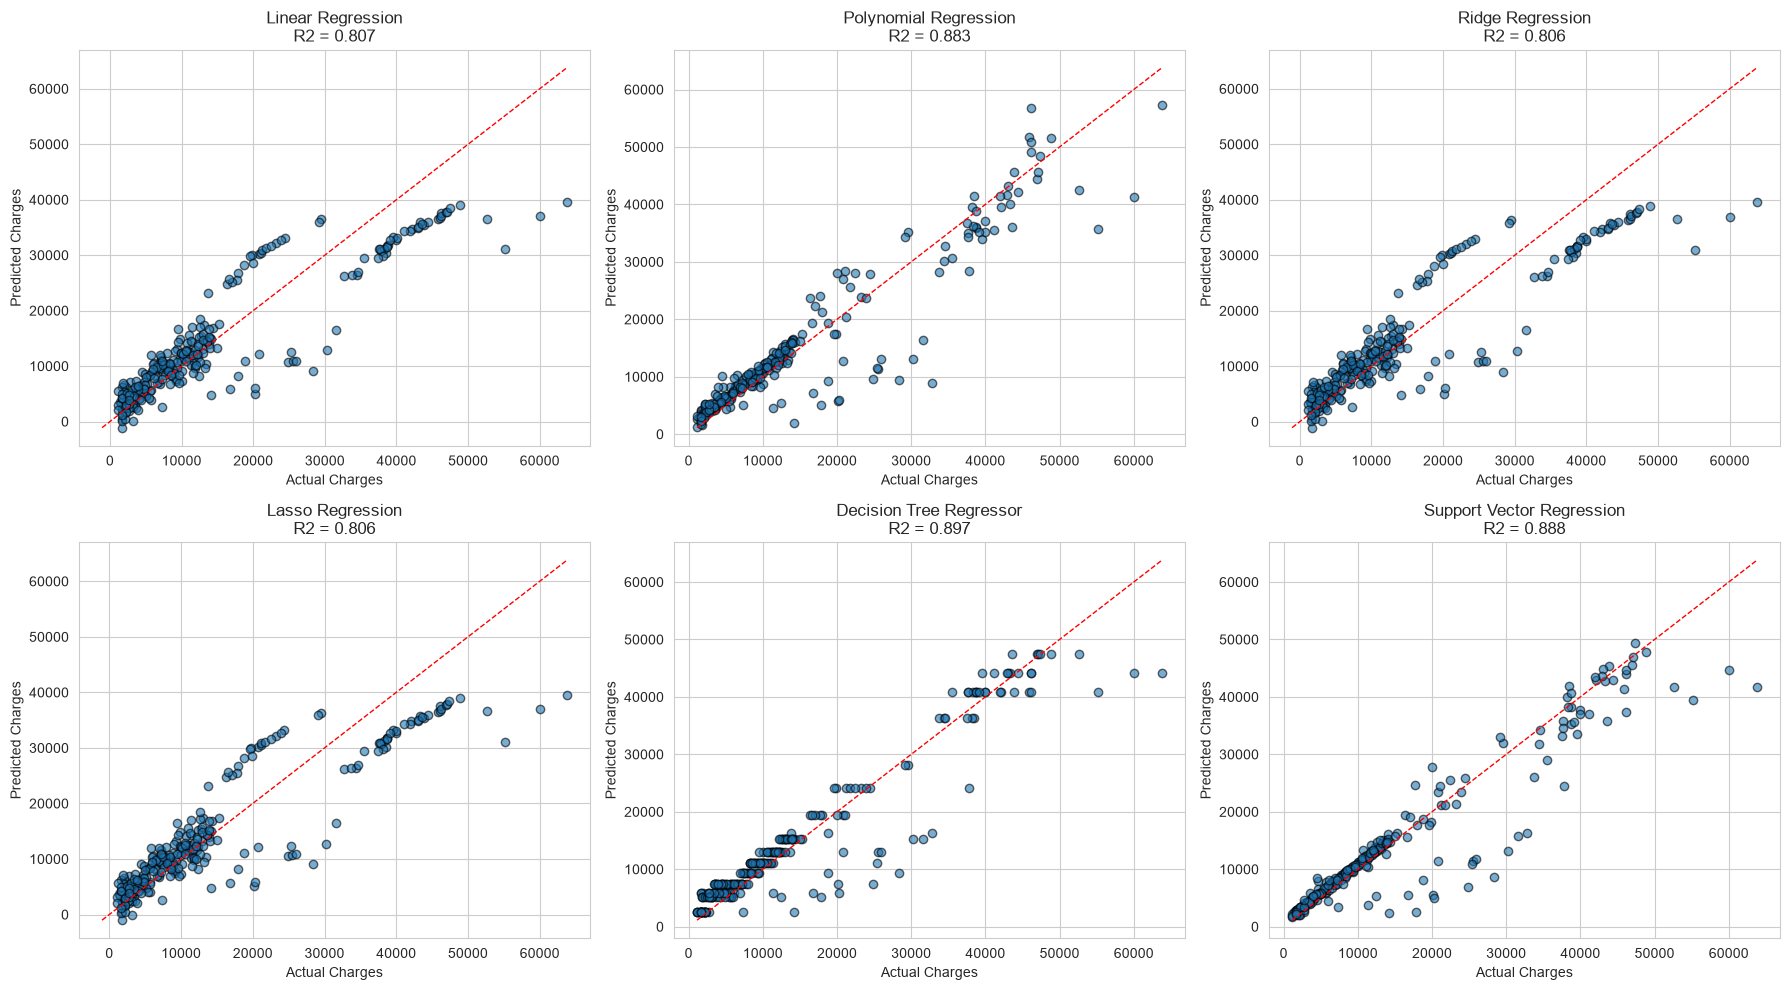

In [26]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.6, edgecolor="k")
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Actual Charges")
    ax.set_ylabel("Predicted Charges")
    ax.set_title(f"{name}\nR2 = {r2_score(y_test, y_pred):.3f}")

plt.tight_layout()
plt.show()


# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.

### Hasil evaluasi pada test set (20%, random_state=42, data 1337 baris setelah drop duplikat)

| Model | Parameter terbaik | MAE | RMSE | R2 |
|---|---|---|---|---|
| Linear Regression | - | 4177.05 | 5956.34 | 0.81 |
| Polynomial Regression | degree = 2 | 2867.32 | 4646.06 | 0.88 |
| Ridge Regression | alpha = 1.0 | 4193.89 | 5971.86 | 0.81 |
| Lasso Regression | alpha = 10 | 4184.38 | 5969.62 | 0.81 |
| Decision Tree Regressor | max_depth = 4, min_samples_leaf = 5 | 2621.31 | 4345.88 | 0.90 |
| Support Vector Regression | C = 10, epsilon = 0.1, gamma = auto | 2396.04 | 4537.54 | 0.89 |

- Linear, Ridge, dan Lasso hasilnya hampir sama (R2 0.81). Setelah one-hot encoding fiturnya cuma 8 dan hubungannya udah relatif linear, jadi regularisasi dengan alpha kecil nggak ngaruh banyak. Alpha yang kegedean (100-1000) malah bikin model underfit, R2 validasi anjlok ke 0.2 bahkan 0.
- Polynomial degree 2 naik signifikan, R2 dari 0.81 jadi 0.88. Degree 3 lebih jelek saat validasi (0.81 vs 0.82) karena fiturnya meledak jadi overfit, makanya yang dipakai degree 2.
- Decision Tree (max_depth 4) dapat R2 paling tinggi (0.90). max_depth dan min_samples_leaf ditentukan lewat validasi 5-fold biar tree-nya nggak hafal data train.
- SVR hampir sejajar (R2 0.89) dan punya MAE paling kecil (2396). Syaratnya fitur dan target harus di-scale dulu. Saat dicoba tanpa scaling target, SVR hampir nggak bisa belajar (R2 cuma 0.05) karena rentang charges (1121 - 63770) terlalu besar buat epsilon dan C.
- Preprocessing: StandardScaler bikin skala semua fitur sama (wajib buat SVR), OneHotEncoder bikin fitur kategori bisa diproses model, dan Decision Tree tetap tanpa scaling karena dia pake threshold.
- Dataset sendiri bersih: 0 missing value, 1 baris duplikat udah di-drop jadi sisa 1337 baris.


# 6. Kesimpulan dan Saran

SARAN :
    - Tambah fitur baru biar model punya informasi lebih, misal umur*bmi atau kategori obesitas.
    - Tuning parameter lebih banyak pake GridSearchCV (alpha, max_depth, kernel SVR) biar ketemu kombinasi yang lebih optimal.
    - Coba model ensemble lain kayak Random Forest atau Gradient Boosting buat bandingin performa.

Kesimpulan :
    - Model terbaik ada 3, yaitu Decision Tree (R2 0.90), SVR (R2 0.89), dan Polynomial (R2 0.88). Linear, Ridge, dan Lasso paling rendah (R2 0.81) karena datanya udah relatif linear dan fiturnya sedikit, jadi regularisasi nggak ngaruh banyak.
    - Preprocessing ngaruh besar terhadap hasil. Scaling bikin SVR bisa jalan (tanpa scaling target hasilnya rusak), one-hot encoding bikin fitur kategori bisa dipake semua model, dan Decision Tree tetep jalan tanpa scaling.
    - Data udah dibersihin dari awal, yaitu 0 missing value dan 1 duplikat di-drop, jadi sisa 1337 baris sebelum di-split jadi train dan test.
